**Configuracion de CPU/GPU**

In [2]:

# Importamos TensorFlow
import tensorflow as tf

# Revisamos si hay una GPU disponible
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU disponible:", gpus[0])
else:
    print("No hay GPU disponible, podemos usar CPU")



No hay GPU disponible; podemos usar CPU.


**Importación de Dataset**

In [3]:

# descargamos el dataset de kaggle
!pip install -q kagglehub

import kagglehub
import os

# guardamos la ruta donde se descargaron las imagenes
ruta_dataset = kagglehub.dataset_download(
    "amandam1/healthy-vs-diseased-leaf-image-dataset"
)

print("dataset descargado en:", ruta_dataset)


100%|██████████| 6.20G/6.20G [01:20<00:00, 82.3MB/s]

Extracting files...


dataset descargado en: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1


**Exploracion de datos**

In [4]:
# revisamos como vienen organizadas las imagenes
for carpeta, subcarpetas, archivos in os.walk(ruta_dataset):
    nivel = carpeta.replace(ruta_dataset, "").count(os.sep)

    if nivel > 2:
        continue

    print("carpeta:", carpeta)
    print("subcarpetas:", subcarpetas[:5])
    print("archivos:", archivos[:5])
    print("----------------------")


carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1
subcarpetas: ['A Database of Leaf Images']
archivos: []
----------------------
carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images
subcarpetas: ['Pongamia Pinnata (P7)', 'Mango (P0)', 'Jatropha (P6)', 'Gauva (P3)', 'Arjun (P1)']
archivos: []
----------------------
carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images/Pongamia Pinnata (P7)
subcarpetas: ['diseased', 'healthy']
archivos: []
----------------------
carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images/Mango (P0)
subcarpetas: ['diseased', 'healthy']
archivos: []
----------------------
carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images/Jatr

In [5]:
# buscamos las carpetas que tengan lemon o limon en el nombre
for carpeta, subcarpetas, archivos in os.walk(ruta_dataset):
    if "lemon" in carpeta.lower() or "limon" in carpeta.lower():
        print("carpeta:", carpeta)
        print("subcarpetas:", subcarpetas)
        print("cantidad de archivos:", len(archivos))
        print("----------------------")


carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images/Lemon (P10)
subcarpetas: ['diseased', 'healthy']
cantidad de archivos: 0
----------------------
carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images/Lemon (P10)/diseased
subcarpetas: []
cantidad de archivos: 77
----------------------
carpeta: /root/.cache/kagglehub/datasets/amandam1/healthy-vs-diseased-leaf-image-dataset/versions/1/A Database of Leaf Images/Lemon (P10)/healthy
subcarpetas: []
cantidad de archivos: 159
----------------------


**Construccion del modelo**

In [6]:
# definimos la ruta donde estan las imagenes de limon
ruta_limon = os.path.join(
    ruta_dataset,
    "A Database of Leaf Images",
    "Lemon (P10)"
)

# cargamos las imagenes para entrenar el modelo
train_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_limon,          # carpeta donde estan las imagenes
    validation_split=0.2, # usamos el 20% para validar y el 80% para entrenar
    subset="training",    # seleccionamos las imagenes de entrenamiento
    seed=42,              # mantenemos la misma division en cada ejecucion
    image_size=(224, 224),# cambiamos el tamaño de las imagenes a 224 x 224
    batch_size=16         # procesamos 16 imagenes por grupo
)

# cargamos las imagenes que usaremos para validar los resultados
val_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_limon,           # usamos la misma carpeta de imagenes
    validation_split=0.2, # reservamos el mismo 20% para validacion
    subset="validation",  # seleccionamos las imagenes de validacion
    seed=42,              # usamos la misma semilla para no cambiar la division
    image_size=(224, 224),# todas las imagenes tendran el mismo tamaño
    batch_size=16         # procesamos 16 imagenes por grupo
)

# mostramos los nombres de las clases que encontro tensorflow
print("clases:", train_ds.class_names)


Found 236 files belonging to 2 classes.
Using 189 files for training.
Found 236 files belonging to 2 classes.
Using 47 files for validation.
clases: ['diseased', 'healthy']


**Visualización de los datos**

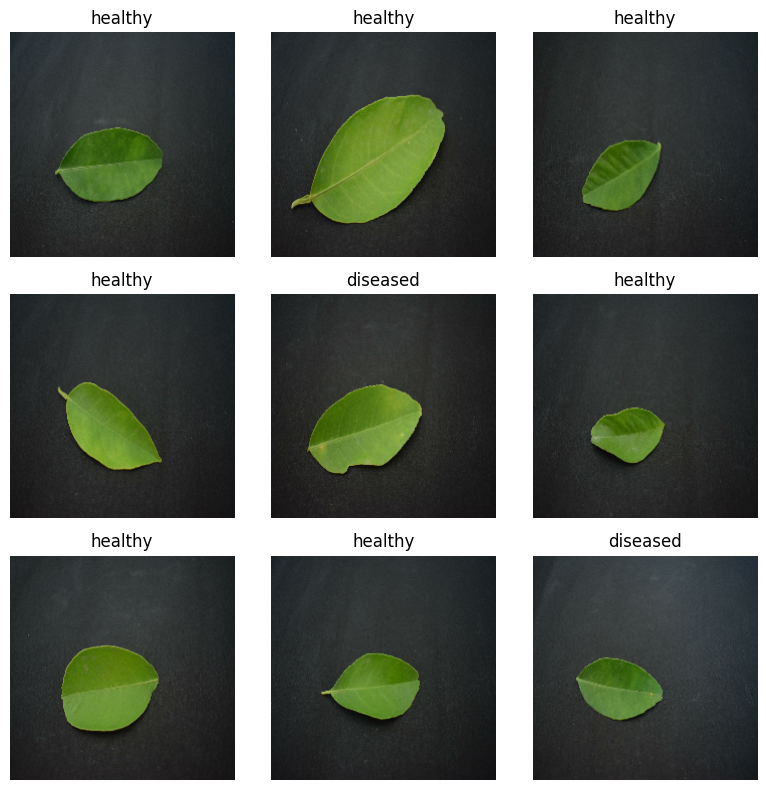

In [7]:
import matplotlib.pyplot as plt

# tomamos un grupo de imagenes del conjunto de entrenamiento
imagenes, etiquetas = next(iter(train_ds))

# mostramos las primeras 9 imagenes
plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)  # acomodamos las imagenes en una cuadricula
    plt.imshow(imagenes[i].numpy().astype("uint8"))  # mostramos la imagen
    plt.title(train_ds.class_names[int(etiquetas[i])])  # mostramos su clase
    plt.axis("off")  # ocultamos los ejes para ver mejor la imagen

plt.tight_layout()
plt.show()


**Login Hugging Face Hub**

In [10]:
# instalamos la libreria para conectarnos a hugging face
!pip install -q huggingface_hub transformers

# importamos la funcion para iniciar sesion
from huggingface_hub import notebook_login

# iniciamos sesion con nuestro token
notebook_login()


**Descarga de modelos desde Hugging Face Lab**

In [16]:
# importamos las herramientas de hugging face
from huggingface_hub import HfApi, hf_hub_download, snapshot_download

# revisamos que la cuenta de hugging face este conectada
api = HfApi()
usuario = api.whoami()
print("cuenta conectada:", usuario["name"])

# descargamos los modelos desde hugging face usando la sesion iniciada
rutas_modelos = {}

# guardamos los repositorios de hugging face que vamos a descargar
repositorios = {
    "ResNet50": "keras/resnet_50_imagenet",
    "EfficientNetB0": "keras/efficientnet_b0_ra_imagenet",
    "MobileNetV3 Small": "keras/mobilenet_v3_small_100_imagenet"
}


for nombre, repo in repositorios.items():
    print("descargando modelo:", nombre)

    # snapshot_download descarga los archivos del repositorio y devuelve su ruta local
    rutas_modelos[nombre] = snapshot_download(
        repo_id=repo,  # repositorio del modelo en hugging face hub
        token=True     # utiliza las credenciales guardadas de nuestra sesion
    )

    print("modelo descargado en:", rutas_modelos[nombre])


cuenta conectada: saulrodriguezg
descargando modelo: ResNet50


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

modelo descargado en: /root/.cache/huggingface/hub/models--keras--resnet_50_imagenet/snapshots/cfc370bc8a3efa7b2259c7c4e5bde18cdbeff092
descargando modelo: EfficientNetB0


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

modelo descargado en: /root/.cache/huggingface/hub/models--keras--efficientnet_b0_ra_imagenet/snapshots/e9658dbecba3601a2ba1bb776e1329688b2c68b2
descargando modelo: MobileNetV3 Small


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

modelo descargado en: /root/.cache/huggingface/hub/models--keras--mobilenet_v3_small_100_imagenet/snapshots/0c0c8625121a1725a05a0ec7d23f0ed22286b3a2


In [17]:
# revisamos que archivos se descargaron de cada modelo
for nombre, ruta in rutas_modelos.items():

    print("\nmodelo:", nombre)
    print("ruta:", ruta)

    # mostramos algunos archivos del repositorio
    for archivo in os.listdir(ruta)[:10]:
        print(" -", archivo)



modelo: ResNet50
ruta: /root/.cache/huggingface/hub/models--keras--resnet_50_imagenet/snapshots/cfc370bc8a3efa7b2259c7c4e5bde18cdbeff092
 - task.weights.h5
 - task.json
 - model.weights.h5
 - README.md
 - .gitattributes
 - config.json
 - image_converter.json
 - preprocessor.json
 - metadata.json

modelo: EfficientNetB0
ruta: /root/.cache/huggingface/hub/models--keras--efficientnet_b0_ra_imagenet/snapshots/e9658dbecba3601a2ba1bb776e1329688b2c68b2
 - task.weights.h5
 - task.json
 - model.weights.h5
 - README.md
 - .gitattributes
 - config.json
 - image_converter.json
 - preprocessor.json
 - metadata.json

modelo: MobileNetV3 Small
ruta: /root/.cache/huggingface/hub/models--keras--mobilenet_v3_small_100_imagenet/snapshots/0c0c8625121a1725a05a0ec7d23f0ed22286b3a2
 - task.weights.h5
 - task.json
 - model.weights.h5
 - README.md
 - .gitattributes
 - config.json
 - image_converter.json
 - preprocessor.json
 - metadata.json


**Carga de Modelos**

In [19]:
# usamos tensorflow como backend de keras
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
import keras_hub

# guardamos las rutas de los modelos que descargamos de hugging face
rutas = {
    "ResNet50": rutas_modelos["ResNet50"],
    "EfficientNetB0": rutas_modelos["EfficientNetB0"],
    "MobileNetV3 Small": rutas_modelos["MobileNetV3 Small"]
}

# guardamos los modelos que logremos cargar
modelos = {}

# intentamos cargar cada modelo desde su carpeta local
for nombre, ruta in rutas.items():
    print("cargando modelo:", nombre)
    # mostramos los archivos para comprobar que la carpeta existe
    print(os.listdir(ruta))
    # cargamos el modelo usando el preset correspondiente
    if nombre == "ResNet50":
        preset = "hf://keras/resnet_50_imagenet"
    elif nombre == "EfficientNetB0":
        preset = "hf://keras/efficientnet_b0_ra_imagenet"
    else:
        preset = "hf://keras/mobilenet_v3_small_100_imagenet"
    # cargamos el modelo preentrenado
    modelos[nombre] = keras_hub.models.ImageClassifier.from_preset(preset)

    print("modelo cargado correctamente")


cargando modelo: ResNet50
['task.weights.h5', 'task.json', 'model.weights.h5', 'README.md', '.gitattributes', 'config.json', 'image_converter.json', 'preprocessor.json', 'metadata.json']
modelo cargado correctamente
cargando modelo: EfficientNetB0
['task.weights.h5', 'task.json', 'model.weights.h5', 'README.md', '.gitattributes', 'config.json', 'image_converter.json', 'preprocessor.json', 'metadata.json']
modelo cargado correctamente
cargando modelo: MobileNetV3 Small
['task.weights.h5', 'task.json', 'model.weights.h5', 'README.md', '.gitattributes', 'config.json', 'image_converter.json', 'preprocessor.json', 'metadata.json']
modelo cargado correctamente


**Entrenamiento de los modelos**

In [24]:
# guardamos los clasificadores que vamos a entrenar
clasificadores = {}

# recorremos los tres modelos preentrenados
for nombre, modelo in modelos.items():
    print("preparando:", nombre)
    # transferencia de aprendizaje: aprovechamos las caracteristicas que el modelo ya aprendio
    base = modelo.backbone
    # congelamos la red para conservar lo aprendido y entrenar solo la nueva capa
    base.trainable = False
    # definimos la entrada para imagenes de 224 x 224 con tres canales de color
    entrada = keras.Input(shape=(224, 224, 3))
    # aplicamos el preprocesamiento que necesita cada modelo
    x = modelo.preprocessor(entrada)
    # extraemos las caracteristicas usando la red preentrenada
    x = base(x, training=False)
    # resumimos las caracteristicas de la imagen
    x = keras.layers.GlobalAveragePooling2D()(x)
    # agregamos una capa nueva para clasificar hojas sanas y enfermas
    salida = keras.layers.Dense(2, activation="softmax")(x)
    # creamos el modelo final para nuestro problema
    clasificador = keras.Model(entrada, salida)
    # configuramos el entrenamiento de la nueva capa
    clasificador.compile(
        optimizer="adam", # metodo para ajustar los pesos
        loss="sparse_categorical_crossentropy", # funcion para clasificacion con etiquetas numericas
        metrics=["accuracy"] # medimos el accuracy
    )
    # guardamos el clasificador para entrenarlo despues
    clasificadores[nombre] = clasificador

print("clasificadores preparados")


preparando: ResNet50
preparando: EfficientNetB0
preparando: MobileNetV3 Small
clasificadores preparados


In [25]:

# guardamos los resultados del entrenamiento
historiales = {}
# entrenamos cada clasificador con las mismas imagenes
for nombre, clasificador in clasificadores.items():
    print("\nentrenando modelo:", nombre)
    # medimos el tiempo que tarda el entrenamiento
    import time
    inicio = time.time()
    # entrenamos con las imagenes y validamos en cada epoca
    historial = clasificador.fit(
        train_ds, # imagenes para entrenar
        validation_data=val_ds, # imagenes para validar
        epochs=5 # numero de vueltas sobre los datos de entrenamiento
    )
    # guardamos el historial para comparar los modelos
    historiales[nombre] = historial
    # mostramos cuanto tardo el entrenamiento
    tiempo = time.time() - inicio
    print("tiempo de entrenamiento:", round(tiempo, 2), "segundos")



entrenando modelo: ResNet50
Epoch 1/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 77s 6s/step - accuracy: 0.6402 - loss: 0.6471 - val_accuracy: 0.7234 - val_loss: 0.5678
Epoch 2/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 87s 6s/step - accuracy: 0.6614 - loss: 0.5949 - val_accuracy: 0.7234 - val_loss: 0.5315
Epoch 3/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 68s 5s/step - accuracy: 0.6878 - loss: 0.5573 - val_accuracy: 0.7660 - val_loss: 0.5116
Epoch 4/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 89s 6s/step - accuracy: 0.7302 - loss: 0.5212 - val_accuracy: 0.8298 - val_loss: 0.4814
Epoch 5/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 81s 6s/step - accuracy: 0.7354 - loss: 0.4956 - val_accuracy: 0.8298 - val_loss: 0.4557
tiempo de entrenamiento: 409.82 segundos

entrenando modelo: EfficientNetB0
Epoch 1/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 53s 3s/step - accuracy: 0.6931 - loss: 0.6153 - val_accuracy: 0.7660 - val_loss: 0.5297
Epoch 2/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.7619 - loss: 0.5148 - val_accuracy: 0.7447 - val_loss: 0.4517
Epoch 3/5
12/12 ━━━━

**Evaluación de modelos**

In [26]:
# importamos las metricas que vamos a utilizar
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import time
import pandas as pd

# guardamos los resultados de cada modelo
resultados = []

# evaluamos los tres clasificadores
for nombre, modelo in clasificadores.items():

    # guardamos las etiquetas reales y las predicciones
    etiquetas_reales = []
    predicciones = []
    tiempos = []

    for imagenes, etiquetas in val_ds:

        # guardamos las etiquetas reales
        etiquetas_reales.extend(etiquetas.numpy())

        # medimos el tiempo de prediccion
        inicio = time.perf_counter()
        probabilidades = modelo.predict(imagenes, verbose=0)
        tiempos.append((time.perf_counter() - inicio) / len(imagenes))

        # elegimos la clase con mayor probabilidad
        predicciones.extend(np.argmax(probabilidades, axis=1))

    # calculamos las metricas de clasificacion
    accuracy = accuracy_score(etiquetas_reales, predicciones)
    precision = precision_score(etiquetas_reales, predicciones, zero_division=0)
    recall = recall_score(etiquetas_reales, predicciones, zero_division=0)
    f1 = f1_score(etiquetas_reales, predicciones, zero_division=0)

    # guardamos los resultados del modelo
    resultados.append({
        "Modelo": nombre,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-score": round(f1, 4),
        "Latencia promedio (ms/imagen)": round(np.mean(tiempos) * 1000, 2)
    })

# mostramos la tabla comparativa
tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados)


,Modelo,Accuracy,Precision,Recall,F1-score,Latencia promedio (ms/imagen)
0,ResNet50,0.8298,0.8095,1.0000,0.8947,554.67
1,EfficientNetB0,0.8511,0.8649,0.9412,0.9014,273.00
2,MobileNetV3 Small,0.8298,0.8611,0.9118,0.8857,281.86


**Matriz de confusión**

In [27]:
# importamos las herramientas para revisar los errores
from sklearn.metrics import classification_report, confusion_matrix

# evaluamos cada modelo por separado
for nombre, modelo in clasificadores.items():

    etiquetas_reales = []
    predicciones = []

    # generamos las predicciones sobre el conjunto de validacion
    for imagenes, etiquetas in val_ds:
        probabilidades = modelo.predict(imagenes, verbose=0)

        etiquetas_reales.extend(etiquetas.numpy())
        predicciones.extend(np.argmax(probabilidades, axis=1))

    print("\nmodelo:", nombre)

    # mostramos precision, recall y f1 para cada clase
    print(classification_report(
        etiquetas_reales,
        predicciones,
        target_names=train_ds.class_names,
        zero_division=0
    ))

    # mostramos los aciertos y errores de cada clase
    print("matriz de confusion:")
    print(confusion_matrix(etiquetas_reales, predicciones))



modelo: ResNet50
              precision    recall  f1-score   support

    diseased       1.00      0.38      0.56        13
     healthy       0.81      1.00      0.89        34

    accuracy                           0.83        47
   macro avg       0.90      0.69      0.73        47
weighted avg       0.86      0.83      0.80        47

matriz de confusion:
[[ 5  8]
 [ 0 34]]

modelo: EfficientNetB0
              precision    recall  f1-score   support

    diseased       0.80      0.62      0.70        13
     healthy       0.86      0.94      0.90        34

    accuracy                           0.85        47
   macro avg       0.83      0.78      0.80        47
weighted avg       0.85      0.85      0.84        47

matriz de confusion:
[[ 8  5]
 [ 2 32]]

modelo: MobileNetV3 Small
              precision    recall  f1-score   support

    diseased       0.73      0.62      0.67        13
     healthy       0.86      0.91      0.89        34

    accuracy                     

**Reporte Técnico de Metricas**

In [28]:
# guardamos las metricas por clase de cada modelo
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

resultados_finales = []

for nombre, modelo in clasificadores.items():

    etiquetas_reales = []
    predicciones = []

    # obtenemos las predicciones del conjunto de validacion
    for imagenes, etiquetas in val_ds:
        probabilidades = modelo.predict(imagenes, verbose=0)
        etiquetas_reales.extend(etiquetas.numpy())
        predicciones.extend(np.argmax(probabilidades, axis=1))

    # calculamos las metricas tomando diseased como clase positiva
    resultados_finales.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(etiquetas_reales, predicciones),
        "Precision diseased": precision_score(
            etiquetas_reales, predicciones, pos_label=0, zero_division=0
        ),
        "Recall diseased": recall_score(
            etiquetas_reales, predicciones, pos_label=0, zero_division=0
        ),
        "F1 diseased": f1_score(
            etiquetas_reales, predicciones, pos_label=0, zero_division=0
        )
    })

# convertimos los resultados en una tabla
tabla_final = pd.DataFrame(resultados_finales)

# guardamos la tabla para el reporte
tabla_final.to_csv("resultados_modelos.csv", index=False)

display(tabla_final)
print("resultados guardados en resultados_modelos.csv")


,Modelo,Accuracy,Precision diseased,Recall diseased,F1 diseased
0,ResNet50,0.829787,1.000000,0.384615,0.555556
1,EfficientNetB0,0.851064,0.800000,0.615385,0.695652
2,MobileNetV3 Small,0.829787,0.727273,0.615385,0.666667


resultados guardados en resultados_modelos.csv


**Latencia**

In [29]:
# guardamos los tiempos de cada modelo
latencias = []

# usamos un lote de imagenes de validacion
imagenes, etiquetas = next(iter(val_ds))

for nombre, modelo in clasificadores.items():

    # hacemos una prediccion inicial para preparar el modelo
    modelo.predict(imagenes, verbose=0)

    tiempos = []

    # repetimos la prediccion varias veces para medir el tiempo
    for _ in range(10):
        inicio = time.perf_counter()
        modelo.predict(imagenes, verbose=0)
        fin = time.perf_counter()

        # calculamos el tiempo por imagen en milisegundos
        tiempo_por_imagen = (fin - inicio) / len(imagenes) * 1000
        tiempos.append(tiempo_por_imagen)

    # guardamos la latencia promedio
    latencias.append({
        "Modelo": nombre,
        "Latencia promedio (ms/imagen)": round(np.mean(tiempos), 2),
        "Desviacion (ms/imagen)": round(np.std(tiempos), 2)
    })

# mostramos los tiempos medidos
tabla_latencias = pd.DataFrame(latencias)
display(tabla_latencias)


,Modelo,Latencia promedio (ms/imagen),Desviacion (ms/imagen)
0,ResNet50,227.20,65.88
1,EfficientNetB0,88.62,29.05
2,MobileNetV3 Small,116.46,38.92


In [30]:
# juntamos las metricas de clasificacion y los tiempos
tabla_comparativa = tabla_final.merge(
    tabla_latencias,
    on="Modelo"
)

# ordenamos los modelos por F1 de la clase enferma
tabla_comparativa = tabla_comparativa.sort_values(
    by="F1 diseased",
    ascending=False
)

# mostramos los resultados
display(tabla_comparativa.round(4))

# guardamos la tabla para usarla en el reporte
tabla_comparativa.to_csv(
    "comparativa_modelos.csv",
    index=False
)

print("tabla guardada en comparativa_modelos.csv")

,Modelo,Accuracy,Precision diseased,Recall diseased,F1 diseased,Latencia promedio (ms/imagen),Desviacion (ms/imagen)
1,EfficientNetB0,0.8511,0.8000,0.6154,0.6957,88.62,29.05
2,MobileNetV3 Small,0.8298,0.7273,0.6154,0.6667,116.46,38.92
0,ResNet50,0.8298,1.0000,0.3846,0.5556,227.20,65.88


tabla guardada en comparativa_modelos.csv


**Comparacion de tamañanos de los modelos**

In [31]:
# calculamos el tamaño de los archivos descargados
import os
import pandas as pd

datos_tamano = []

for nombre, ruta in rutas_modelos.items():
    # sumamos el tamaño de todos los archivos del modelo
    tamano_bytes = 0

    for carpeta, subcarpetas, archivos in os.walk(ruta):
        for archivo in archivos:
            ruta_archivo = os.path.join(carpeta, archivo)
            tamano_bytes += os.path.getsize(ruta_archivo)

    # convertimos el tamaño a megabytes
    tamano_mb = tamano_bytes / (1024 ** 2)

    datos_tamano.append({
        "Modelo": nombre,
        "Tamaño descargado (MB)": round(tamano_mb, 2)
    })

tabla_tamanos = pd.DataFrame(datos_tamano)
display(tabla_tamanos)

,Modelo,Tamaño descargado (MB)
0,ResNet50,188.44
1,EfficientNetB0,36.91
2,MobileNetV3 Small,14.13


**Licencias y compatibilidad**

In [32]:
# consultamos la informacion de cada modelo en Hugging Face
from huggingface_hub import model_info
import pandas as pd

datos_modelos = []

for nombre, repo in repositorios.items():
    info = model_info(repo)

    datos_modelos.append({
        "Modelo": nombre,
        "Repositorio": repo,
        "Licencia": info.card_data.get("license") if info.card_data else "No especificada"
    })

tabla_licencias = pd.DataFrame(datos_modelos)
display(tabla_licencias)

,Modelo,Repositorio,Licencia
0,ResNet50,keras/resnet_50_imagenet,apache-2.0
1,EfficientNetB0,keras/efficientnet_b0_ra_imagenet,apache-2.0
2,MobileNetV3 Small,keras/mobilenet_v3_small_100_imagenet,None


In [33]:
# revisamos los metadatos completos de MobileNetV3 Small
from huggingface_hub import model_info

info = model_info("keras/mobilenet_v3_small_100_imagenet")

print("Repositorio:", info.id)
print("Licencia:", info.card_data.get("license") if info.card_data else "No especificada")
print("URL:", info.card_data.get("license") if info.card_data else "Revisar la ficha del modelo")
print("Ficha del modelo: https://huggingface.co/keras/mobilenet_v3_small_100_imagenet")

Repositorio: keras/mobilenet_v3_small_100_imagenet
Licencia: None
URL: None
Ficha del modelo: https://huggingface.co/keras/mobilenet_v3_small_100_imagenet


**Inferencia**

In [35]:
# funcion para clasificar una imagen con uno de los modelos
import numpy as np
import keras
import os

def predecir_hoja(ruta_imagen, nombre_modelo):
    # cargamos la imagen al tamaño usado durante el entrenamiento
    imagen = keras.utils.load_img(
        ruta_imagen,
        target_size=(224, 224)
    )

    # convertimos la imagen a un arreglo
    imagen = keras.utils.img_to_array(imagen)
    imagen = np.expand_dims(imagen, axis=0)

    # obtenemos las probabilidades del modelo
    modelo = clasificadores[nombre_modelo]
    probabilidades = modelo.predict(imagen, verbose=0)[0]

    # identificamos la clase con mayor probabilidad
    indice = np.argmax(probabilidades)
    clase = train_ds.class_names[indice]
    confianza = probabilidades[indice] * 100

    print("Modelo:", nombre_modelo)
    print("Prediccion:", clase)
    print("Confianza:", round(float(confianza), 2), "%")

In [37]:
# probamos el modelo con una imagen de ejemplo
import os

carpeta_enfermas = os.path.join(ruta_limon, "diseased")
archivo = os.listdir(carpeta_enfermas)[0]
ruta_ejemplo = os.path.join(carpeta_enfermas, archivo)

# mostramos la prediccion del modelo
predecir_hoja(ruta_ejemplo, "EfficientNetB0")

# conclusiones parciales de los experimentos

Modelo: EfficientNetB0
Prediccion: healthy
Confianza: 78.92 %
CONCLUSIONES PARCIALES
- EfficientNetB0 obtuvo el mejor accuracy: 85.11%.
- EfficientNetB0 tuvo la menor latencia: 88.62 ms por imagen.
- Su recall para hojas enfermas fue de 61.54%.
- MobileNetV3 Small fue el modelo mas ligero: 14.13 MB.
- ResNet50 no detecto 8 de las 13 hojas enfermas de validacion.
- EfficientNetB0 tambien puede generar falsos negativos.
- Los resultados son preliminares por el tamaño reducido del dataset.


**Conclusiones parciales**

In [38]:
# conclusiones parciales de los experimentos

print("CONCLUSIONES PARCIALES")
print("- EfficientNetB0 obtuvo el mejor accuracy: 85.11%.")
print("- EfficientNetB0 tuvo la menor latencia: 88.62 ms por imagen.")
print("- Su recall para hojas enfermas fue de 61.54%.")
print("- MobileNetV3 Small fue el modelo mas ligero: 14.13 MB.")
print("- ResNet50 no detecto 8 de las 13 hojas enfermas de validacion.")
print("- EfficientNetB0 tambien puede generar falsos negativos.")
print("- Los resultados son preliminares por el tamaño reducido del dataset.")

CONCLUSIONES PARCIALES
- EfficientNetB0 obtuvo el mejor accuracy: 85.11%.
- EfficientNetB0 tuvo la menor latencia: 88.62 ms por imagen.
- Su recall para hojas enfermas fue de 61.54%.
- MobileNetV3 Small fue el modelo mas ligero: 14.13 MB.
- ResNet50 no detecto 8 de las 13 hojas enfermas de validacion.
- EfficientNetB0 tambien puede generar falsos negativos.
- Los resultados son preliminares por el tamaño reducido del dataset.
